# 44. Leave-one-coin-out (LOCO) robustness of the notebook 43 altcoin results

As a follow-up to notebook 43, I check whether a single coin, in particular EOS, drives the equal-weight average over ten altcoins in notebook 43. I leave out each coin once and recompute the equal-weight average of the remaining nine coins, with 95% percentile intervals from the same 1,000-draw bootstrap of common 7-day calendar blocks as in notebook 43.

- Data: the per-coin `*_parts.npz` files and their `_meta.json` in `btc_lead_cost_results_77months_spot/altcoin_dev_period_v1/coins/`, which notebook 43 wrote for the development period. I reuse them without retraining the notebook 17 models.
- Quantities: for the 24-hour event definition, the GBM − M0 differences in standard AUC, pre-onset AUC, in-progress AUC and within-regime pre-onset AUC; secondarily, the 4-hour results and `S_in`, M0's share of excess AUC from in-progress positives.
- Statistical unit: coins with equal weight. Each resample applies the same 7-day block weights to all ten coins, which partly preserves common market shocks, and all ten leave-out scenarios share the same 1,000 resamples.
- Status: I designed this exploratory post hoc sensitivity analysis after I saw the large EOS contribution, so it is neither a new independent holdout nor a confirmatory test. The intervals describe the resampling uncertainty of each nine-coin aggregate.
- Results folder: `altcoin_dev_period_loco_v1`.

In [1]:
from pathlib import Path
import hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: BASE below must point to the actual data folder.')

BASE = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
SOURCE = BASE / 'altcoin_dev_period_v1'
DEST = BASE / 'altcoin_dev_period_loco_v1'

COINS = ['ETHUSDT','XRPUSDT','LTCUSDT','BNBUSDT','ADAUSDT','EOSUSDT','TRXUSDT','ETCUSDT','XLMUSDT','NEOUSDT']
SCORES = {'M0':'M0_VF_logit', 'GBM':'M3_GBM_rich'}
H_LIST = [240, 1440]
DIFF_METRICS = ['auc_standard','auc_pre','auc_in','auc_pre_within_regime']
SEED, N_BOOT, N_BLOCKS = 20261143, 1000, 174
NEEDED = ['C_pre','C_in','P_pre','P_in','N','Cs_pre','Pq_pre','Nq']
FIN_THRESHOLD = 0.95

# Stop unless the notebook 43 sources and completion status are verified.
for rel in ['43_SPEC.json', '43_SUMMARY.json', '1_per_coin.csv', '2_pooled.csv']:
    if not (SOURCE / rel).is_file():
        raise FileNotFoundError(f'Notebook 43 result file missing: {SOURCE / rel}')
spec_bytes = (SOURCE / '43_SPEC.json').read_bytes()
spec43 = json.loads(spec_bytes)
sum43 = json.loads((SOURCE / '43_SUMMARY.json').read_text())
sha43 = hashlib.sha256(spec_bytes).hexdigest()
assert sha43 == sum43['spec_sha256'], '43_SPEC.json SHA differs from the value recorded in 43_SUMMARY.json.'
assert spec43['seed'] == SEED, 'Notebook 43 seed differs from the expected value.'
assert spec43['evaluation']['bootstrap'].startswith('1000 draws of 7-day calendar blocks common to all coins'), 'Notebook 43 bootstrap setting has changed.'
assert spec43['coins'] == COINS == sum43['coins_included'], 'Included coins or their order differ from notebook 43.'
assert not sum43['coins_excluded'], 'Notebook 43 excluded some coins; this analysis does not apply as written.'
assert not sum43['mock_bypass_used'], 'Notebook 43 used a guard bypass.'
assert len(sum43['guards']) > 0 and all(g['passed'] and not g['bypassed_in_mock'] for g in sum43['guards']), 'Some notebook 43 guards failed or were bypassed.'

PARTS = {}
parts_hashes = {}
for sym in COINS:
    mfile = SOURCE / 'coins' / f'{sym}_meta.json'
    pfile = SOURCE / 'coins' / f'{sym}_parts.npz'
    if not mfile.is_file() or not pfile.is_file():
        raise FileNotFoundError(f'{sym}: the notebook 43 per-coin meta/parts files are required: {pfile}')
    meta = json.loads(mfile.read_text())
    assert not meta.get('excluded'), f'{sym} was excluded in notebook 43'
    assert meta.get('symbol') == sym, f'{sym}: meta symbol mismatch'
    assert meta.get('spec_sha256') == sha43, f'{sym}: 43 SPEC SHA mismatch'
    assert meta.get('frozen_sha256') == sum43['frozen_sha256'], f'{sym}: frozen model SHA mismatch'
    with np.load(pfile, allow_pickle=False) as z:
        for h in H_LIST:
            for name in SCORES.values():
                prefix = f'{h}|{name}|'
                try:
                    d = {k: np.array(z[prefix+k], dtype=np.float64, copy=True) for k in NEEDED}
                except KeyError as exc:
                    raise RuntimeError(f'{sym}: missing parts: {exc}')
                for k in ('C_pre', 'C_in', 'Cs_pre'):
                    assert d[k].shape == (N_BLOCKS, N_BLOCKS), (sym,h,name,k,d[k].shape)
                for k in ('P_pre', 'P_in', 'N'):
                    assert d[k].shape == (N_BLOCKS,), (sym,h,name,k,d[k].shape)
                for k in ('Pq_pre','Nq'):
                    assert d[k].shape == (10, N_BLOCKS), (sym,h,name,k,d[k].shape)
                PARTS[(sym,h,name)] = d
    parts_hashes[sym] = hashlib.sha256(pfile.read_bytes()).hexdigest()
print(f'Notebook 43: {len(COINS)} coins, all {len(sum43["guards"])} guards passed, SPEC SHA {sha43[:16]}…')
print('Loaded the notebook 43 7-day block pair-count files without downloading data again.')

Mounted at /content/drive
Notebook 43: 10 coins, all 191 guards passed, SPEC SHA e1e10288ceb9a2d4…
Loaded the notebook 43 7-day block pair-count files without downloading data again.


## 1. Per-coin AUCs on the same resamples as the notebook 43 bootstrap

I regenerate the resampling weights with the same `numpy.random.default_rng(20261143)` and `bincount` scheme as notebook 43 and apply the existing `stats_from` formulas to all resamples at once as array operations.

In [2]:
start = time.time()
rng = np.random.default_rng(SEED)
W = np.vstack([np.ones(N_BLOCKS)] + [
    np.bincount(rng.integers(0, N_BLOCKS, N_BLOCKS), minlength=N_BLOCKS).astype(float)
    for _ in range(N_BOOT)
]) # shape=(1001, 174): row 0 is the point estimate, rows 1..1000 are the notebook 43 bootstrap draws
assert W.shape == (N_BOOT+1, N_BLOCKS)


def ratio(a, b):
    """Notebook 43's `_ratio(a,b)`: computed only where the denominator is positive; extended to arrays."""
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    out = np.full(a.shape, np.nan, dtype=float)
    np.divide(a, b, out=out, where=b > 0)
    return out


def quad(C):
    """w'Cw for every common-calendar bootstrap draw (q in notebook 43's stats_from)."""
    return np.einsum('bi,bi->b', W @ C, W, optimize=True)


def stat_vectors(P):
    wp = W @ P['P_pre']; wi = W @ P['P_in']; wn = W @ P['N']
    cp = quad(P['C_pre']); ci = quad(P['C_in'])
    auc_std = ratio(cp + ci, (wp + wi) * wn)
    auc_pre = ratio(cp, wp * wn)
    auc_in = ratio(ci, wi * wn)
    pi = ratio(wi, wp + wi)
    pq = W @ P['Pq_pre'].T
    nq = W @ P['Nq'].T
    auc_pre_regime = ratio(quad(P['Cs_pre']), (pq * nq).sum(axis=1))
    return {
        'auc_standard':auc_std, 'auc_pre':auc_pre, 'auc_in':auc_in,
        'auc_pre_within_regime':auc_pre_regime, 'share_in':pi,
    }

VECTORS = {key:stat_vectors(value) for key,value in PARTS.items()}
print('Per-coin AUC vectors computed:', len(VECTORS), 'combinations,', f'{time.time()-start:.1f}s')

Per-coin AUC vectors computed: 40 combinations, 0.3s


## 2. Reproduction of the full ten-coin notebook 43 results

Here I recompute the point estimates and 95% intervals saved in notebook 43's `1_per_coin.csv` and `2_pooled.csv`.

In [3]:
reference_coin = pd.read_csv(SOURCE / '1_per_coin.csv')
reference_pool = pd.read_csv(SOURCE / '2_pooled.csv')


def pooled_diff(keep, h, metric):
    """As in notebook 43: per-coin GBM-M0 difference -> equal-weight nanmean."""
    raw = np.stack([VECTORS[(s,h,SCORES['GBM'])][metric] -
                    VECTORS[(s,h,SCORES['M0'])][metric] for s in keep])
    with np.errstate(all='ignore'):
        return np.nanmean(raw, axis=0)


def pooled_sin(keep):
    """Pooled S_in of notebook 43 = mean(pi*(AUCin-.5)) / mean(AUCstd-.5); only the same valid triples are used."""
    h=240; mn=SCORES['M0']; numer=[]; denom=[]
    for sym in keep:
        d=VECTORS[(sym,h,mn)]
        valid=np.isfinite(d['share_in']) & np.isfinite(d['auc_in']) & np.isfinite(d['auc_standard'])
        numer.append(np.where(valid, d['share_in']*(d['auc_in']-0.5), np.nan))
        denom.append(np.where(valid, d['auc_standard']-0.5, np.nan))
    with np.errstate(all='ignore'):
        n=np.nanmean(np.stack(numer), axis=0)
        dd=np.nanmean(np.stack(denom), axis=0)
    return ratio(n, dd)


def bounds(v):
    v=np.asarray(v, float)
    valid=np.isfinite(v[1:])
    if not valid.any():
        return [float(v[0]), np.nan, np.nan, 0.]
    lo,hi=np.percentile(v[1:][valid], [2.5, 97.5])
    return [float(v[0]), float(lo), float(hi), float(valid.mean())]


# Per-coin 43_reference validation, including percentile endpoints.
checks=[]
for s in COINS:
    for h in H_LIST:
        for name in SCORES.values():
            for met in DIFF_METRICS:
                row=reference_coin[(reference_coin.coin==s)&(reference_coin.H==h)&
                                  (reference_coin.score==name)&(reference_coin.quantity==met)]
                assert len(row)==1, f'43 per_coin.csv missing/duplicate: {s,h,name,met}'
                exp=row.iloc[0]
                got=bounds(VECTORS[(s,h,name)][met])
                for field,val in zip(['point','lo','hi','share_draws_finite'],got):
                    if pd.notna(exp[field]) and np.isfinite(val):
                        assert abs(float(exp[field])-val)<1e-10, f'43 per-coin reproduction failed: {s,h,name,met,field,exp[field],val}'
                    else:
                        assert pd.isna(exp[field]) and np.isnan(val), f'43 NaN mismatch: {s,h,name,met,field}'
                checks.append((s,h,name,met))

# Pooled GBM-M0 43_reference validation, including percentile endpoints.
for h in H_LIST:
    for met in DIFF_METRICS:
        ref=reference_pool[(reference_pool.H==h)&(reference_pool.score=='GBM-M0')&(reference_pool.quantity==met)]
        assert len(ref)==1, f'43 pooled.csv missing/duplicate: {h,met}'
        row=ref.iloc[0]; got=bounds(pooled_diff(COINS,h,met))
        for field, val in zip(['point','lo','hi','share_draws_finite'], got):
            assert np.isfinite(val) and abs(float(row[field])-val)<1e-10, f'43 pooled reproduction failed: {h,met,field,float(row[field]),val}'
        checks.append(('pooled',h,'GBM-M0',met))

ref=reference_pool[(reference_pool.H==240)&(reference_pool.score==SCORES['M0'])&
                   (reference_pool.quantity=='S_in_pooled')]
assert len(ref)==1
row=ref.iloc[0]; got=bounds(pooled_sin(COINS))
for field, val in zip(['point','lo','hi','share_draws_finite'], got):
    assert np.isfinite(val) and abs(float(row[field])-val)<1e-10, f'43 pooled S_in reproduction failed: {field,float(row[field]),val}'
checks.append(('pooled',240,'M0','S_in_pooled'))
print(f'PASS: notebook 43 results reproduced for {len(checks)} quantities (point estimate, 95% interval, finite-draw share)')
print('Notebook 43: GBM−M0, 24h standard AUC', bounds(pooled_diff(COINS,1440,'auc_standard')))
print('Notebook 43: GBM−M0, 24h pre-onset AUC', bounds(pooled_diff(COINS,1440,'auc_pre')))
print('Notebook 43: M0 S_in, 4h', bounds(pooled_sin(COINS)))

PASS: notebook 43 results reproduced for 169 quantities (point estimate, 95% interval, finite-draw share)
Notebook 43: GBM−M0, 24h standard AUC [0.03774220046542178, 0.01564763489465827, 0.061832396372163784, 1.0]
Notebook 43: GBM−M0, 24h pre-onset AUC [-0.0368326807020052, -0.085156625416349, 0.019597692990389097, 1.0]
Notebook 43: M0 S_in, 4h [0.6923383105107341, 0.6336824822561176, 0.7521327825824757, 1.0]


## 3. Ten LOCO scenarios and the full ten-coin baseline

Each row gives the equal-weight average of the nine coins that remain when I remove one coin, on the same 1,000 common-block resamples as in notebook 43. I record descriptively whether each 95% interval contains 0, with no family-wise error adjustment across the post hoc LOCO comparisons.

In [4]:
result_rows=[]
for left_out in ['NONE'] + COINS:
    keep=[c for c in COINS if c!=left_out]
    for h in H_LIST:
        for metric in DIFF_METRICS:
            point,lo,hi,fin=bounds(pooled_diff(keep,h,metric))
            result_rows.append(dict(left_out=left_out, n_coins=len(keep), H=h, model_difference='GBM-M0',
                                    metric=metric, point=point, ci_lo=lo, ci_hi=hi,
                                    finite_boot_share=fin, positive_ci=(fin>=FIN_THRESHOLD and lo>0),
                                    negative_ci=(fin>=FIN_THRESHOLD and hi<0)))
    point,lo,hi,fin=bounds(pooled_sin(keep))
    result_rows.append(dict(left_out=left_out, n_coins=len(keep), H=240, model_difference='M0',
                            metric='S_in_pooled', point=point, ci_lo=lo, ci_hi=hi,
                            finite_boot_share=fin, positive_ci=(fin>=FIN_THRESHOLD and lo>0),
                            negative_ci=(fin>=FIN_THRESHOLD and hi<0)))
ALL_RESULTS=pd.DataFrame(result_rows)

summaries=[]
for outcoin in ['NONE'] + COINS:
    z=ALL_RESULTS[(ALL_RESULTS.left_out==outcoin)&(ALL_RESULTS.H==1440)]
    g=lambda met: z[z.metric==met].iloc[0]
    a,p,inn,reg=(g(met) for met in DIFF_METRICS)
    summaries.append(dict(left_out=outcoin, n_coins=10 if outcoin=='NONE' else 9,
        std_diff=a.point, std_lo=a.ci_lo, std_hi=a.ci_hi, std_finite=a.finite_boot_share,
        pre_diff=p.point, pre_lo=p.ci_lo, pre_hi=p.ci_hi, pre_finite=p.finite_boot_share,
        in_diff=inn.point, in_lo=inn.ci_lo, in_hi=inn.ci_hi,
        pre_reg_diff=reg.point, pre_reg_lo=reg.ci_lo, pre_reg_hi=reg.ci_hi,
        sign_reversal=bool(a.point>0 and p.point<0),
        std_gbm_advantage_95=bool(a.positive_ci),
        pre_m0_advantage_95=bool(p.negative_ci),
        both_legs_95=bool(a.positive_ci and p.negative_ci)))
R24=pd.DataFrame(summaries)

print('24h: GBM − M0 (LOCO, 95% common-block bootstrap interval)')
display(R24[['left_out','n_coins','std_diff','std_lo','std_hi','pre_diff','pre_lo','pre_hi','std_gbm_advantage_95','pre_m0_advantage_95']].round(4))
print('\n4h M0 share of excess AUC from in-progress positives, S_in')
display(ALL_RESULTS[(ALL_RESULTS.H==240)&(ALL_RESULTS.metric=='S_in_pooled')][['left_out','point','ci_lo','ci_hi']].round(4))

24h: GBM − M0 (LOCO, 95% common-block bootstrap interval)


,left_out,n_coins,std_diff,std_lo,std_hi,pre_diff,pre_lo,pre_hi,std_gbm_advantage_95,pre_m0_advantage_95
0,NONE,10,0.0377,0.0156,0.0618,-0.0368,-0.0852,0.0196,True,False
1,ETHUSDT,9,0.0503,0.0254,0.0768,-0.0388,-0.0868,0.0198,True,False
2,XRPUSDT,9,0.0395,0.0165,0.0644,-0.0411,-0.0927,0.0167,True,False
3,LTCUSDT,9,0.0342,0.0106,0.0597,-0.0325,-0.0853,0.0278,True,False
4,BNBUSDT,9,0.0616,0.0372,0.0877,-0.0289,-0.0739,0.0158,True,False
5,ADAUSDT,9,0.0454,0.0212,0.0715,-0.0206,-0.0701,0.0393,True,False
6,EOSUSDT,9,0.0189,-0.0039,0.0416,-0.0460,-0.0990,0.0151,False,False
7,TRXUSDT,9,0.0286,0.0047,0.0535,-0.0453,-0.0989,0.0157,True,False
8,ETCUSDT,9,0.0368,0.0161,0.0593,-0.0418,-0.0921,0.0161,True,False
9,XLMUSDT,9,0.0216,0.0009,0.0435,-0.0473,-0.0967,0.0108,True,False



4h M0 share of excess AUC from in-progress positives, S_in


,left_out,point,ci_lo,ci_hi
8,NONE,0.6923,0.6337,0.7521
17,ETHUSDT,0.6846,0.6204,0.7498
26,XRPUSDT,0.7003,0.6465,0.7573
35,LTCUSDT,0.6933,0.6355,0.7510
44,BNBUSDT,0.6898,0.6275,0.7537
53,ADAUSDT,0.6930,0.6352,0.7521
62,EOSUSDT,0.6938,0.6336,0.7550
71,TRXUSDT,0.6877,0.6269,0.7458
80,ETCUSDT,0.6847,0.6261,0.7473
89,XLMUSDT,0.7030,0.6469,0.7597


## 4. Saved results and summary

In [5]:
DEST.mkdir(parents=True, exist_ok=True)
analysis_spec = {
    'analysis':'44 — leave-one-coin-out of frozen notebook-43 10-altcoin equal-weight AUC evaluation',
    'status':'exploratory and post hoc; EOS influence known before designing LOCO; not preregistered',
    'source_folder':str(SOURCE), 'source_spec43_sha256':sha43,
    'source_frozen_sha256':sum43['frozen_sha256'],
    'source_summary43_sha256':hashlib.sha256((SOURCE/'43_SUMMARY.json').read_bytes()).hexdigest(),
    'coin_parts_sha256':parts_hashes,
    'coins':COINS, 'left_out':['NONE']+COINS,
    'horizons_minutes':H_LIST, 'target':'GBM minus M0 per-minute AUC; ancillary M0 S_in at 4h',
    'aggregation':'equal weight among retained coins, nanmean across valid coins within each draw',
    'bootstrap':'exact same 1,000 common 7-day calendar block draws as notebook 43 (seed 20261143); fixed per-coin parts; percentile 95% intervals',
    'guard':'point, CI endpoints and finite share of 43 per-coin and pooled results must reproduce within 1e-10',
    'difference_metrics':DIFF_METRICS,
    'finite_share_min_for_interval_reading':FIN_THRESHOLD,
    'interpretation':'LOCO interval changes are exploratory; no per-coin selection or confirmatory multiple-testing claim',
}
sp_bytes=(json.dumps(analysis_spec,indent=2,sort_keys=True,ensure_ascii=False)+'\n').encode('utf-8')
sp_path=DEST/'44_SPEC.json'
if sp_path.exists() and sp_path.read_bytes()!=sp_bytes:
    raise RuntimeError('44_SPEC.json differs from the stored spec; use a separate folder or check the stored one.')
sp_path.write_bytes(sp_bytes)
ALL_RESULTS.to_csv(DEST/'44_LOCO_all_metrics.csv',index=False)
R24.to_csv(DEST/'44_LOCO_24h.csv',index=False)

others=R24[R24.left_out!='NONE'].copy()
no_eos=R24[R24.left_out=='EOSUSDT'].iloc[0]
base=R24[R24.left_out=='NONE'].iloc[0]
summary={
 'source_spec43_sha256':sha43,
 'verified_43_reference_checks':len(checks),
 'n_bootstrap_draws':N_BOOT,
 'n_coins':len(COINS),
 'base_24h':base.to_dict(),
 'exclude_EOS_24h':no_eos.to_dict(),
 'all_exclusions_standard_CI_above_zero':bool(others.std_gbm_advantage_95.all()),
 'num_exclusions_standard_CI_above_zero':int(others.std_gbm_advantage_95.sum()),
 'num_exclusions_pre_M0_CI_below_zero':int(others.pre_m0_advantage_95.sum()),
 'num_exclusions_both_legs_CI':int(others.both_legs_95.sum()),
 'LOCO_rows':R24.to_dict('records'),
 'warnings':['Post hoc, exploratory deletion sensitivity analysis. Not independent samples.',
             'Shared-market dependence partially preserved via common week bootstrap; coin-universe uncertainty not sampled.',
             'Equal-weight coin pooling mirrors notebook 43; not an event-weighted or minute-weighted pooled AUC.',
             'The 43 AUC analyses score per-minute discrimination, not fixed-budget realized economic utility.'],
}
# convert numpy.bool_ or np scalars for JSON, fail explicitly on unexpected structures
summary=json.loads(json.dumps(summary,default=lambda x:x.item() if isinstance(x,np.generic) else str(x),allow_nan=False))
(DEST/'44_SUMMARY.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
print('\nNotebook 44 main results:')
print(f'All 10 coins: 24h standard AUC difference {base.std_diff:+.4f} [{base.std_lo:+.4f}, {base.std_hi:+.4f}]')
print(f'Without EOS, 9 coins: 24h standard AUC difference {no_eos.std_diff:+.4f} [{no_eos.std_lo:+.4f}, {no_eos.std_hi:+.4f}]')
print(f'Of 10 LOCO rows, standard AUC interval above 0: {summary["num_exclusions_standard_CI_above_zero"]}/10')
print(f'Of 10 LOCO rows, M0 pre-onset AUC advantage (interval below 0): {summary["num_exclusions_pre_M0_CI_below_zero"]}/10')
print(f'Of 10 LOCO rows, both legs of the reversal with intervals excluding 0: {summary["num_exclusions_both_legs_CI"]}/10')
print('Saved to:',DEST)


Notebook 44 main results:
All 10 coins: 24h standard AUC difference +0.0377 [+0.0156, +0.0618]
Without EOS, 9 coins: 24h standard AUC difference +0.0189 [-0.0039, +0.0416]
Of 10 LOCO rows, standard AUC interval above 0: 9/10
Of 10 LOCO rows, M0 pre-onset AUC advantage (interval below 0): 0/10
Of 10 LOCO rows, both legs of the reversal with intervals excluding 0: 0/10
Saved to: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/altcoin_dev_period_loco_v1


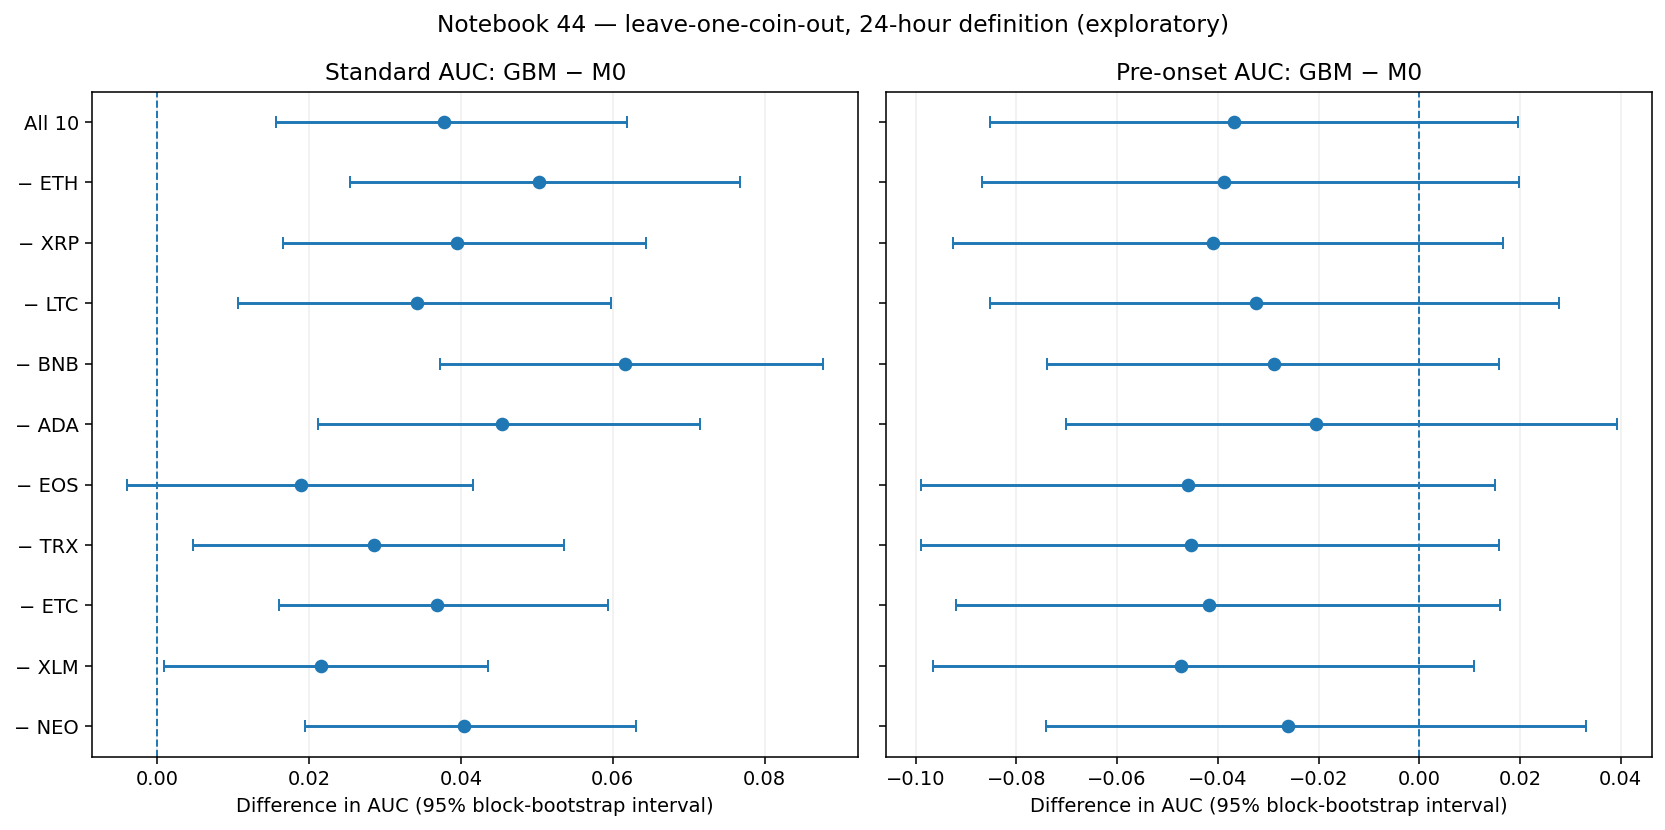

Notebook 43 results left unchanged. Wrote 44_SPEC.json, 44_LOCO_all_metrics.csv, 44_LOCO_24h.csv, 44_SUMMARY.json, 44_LOCO_24h.png/pdf.


In [6]:
show = R24.copy()
labels=['All 10' if s=='NONE' else '− '+s.replace('USDT','') for s in show.left_out]
y=np.arange(len(show))
fig,axs=plt.subplots(1,2,figsize=(12,6),dpi=140,sharey=True)
for ax,metric,lo,hi,title in [
    (axs[0],'std_diff','std_lo','std_hi','Standard AUC: GBM − M0'),
    (axs[1],'pre_diff','pre_lo','pre_hi','Pre-onset AUC: GBM − M0'),
]:
    vals=show[metric].to_numpy(float)
    le=(vals-show[lo].to_numpy(float)).clip(min=0)
    he=(show[hi].to_numpy(float)-vals).clip(min=0)
    ax.errorbar(vals,y,xerr=np.stack([le,he]),fmt='o',capsize=3)
    ax.axvline(0,ls='--',linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Difference in AUC (95% block-bootstrap interval)')
    ax.grid(axis='x',alpha=.2)
axs[0].set_yticks(y,labels)
axs[0].invert_yaxis()
fig.suptitle('Notebook 44 — leave-one-coin-out, 24-hour definition (exploratory)')
fig.tight_layout()
fig.savefig(DEST/'44_LOCO_24h.png',bbox_inches='tight')
fig.savefig(DEST/'44_LOCO_24h.pdf',bbox_inches='tight')
plt.show()
print('Notebook 43 results left unchanged. Wrote 44_SPEC.json, 44_LOCO_all_metrics.csv, 44_LOCO_24h.csv, 44_SUMMARY.json, 44_LOCO_24h.png/pdf.')

## Interpretation
I read the standard and pre-onset AUC differences separately. As in notebook 43, I compute AUCs per coin first and then average them with equal weight; the result is neither a single AUC over the concatenated coins nor an event-weighted average. Every LOCO row is a post hoc sensitivity analysis of per-coin models from the same development period, and its resampling interval reflects variability within the observed coins and period, not generalization to a new population of coins. The main outputs are `44_SUMMARY.json` and `44_LOCO_24h.csv`.